In [1]:
pip install matplotlib numpy ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def iq_plotter(i_value=0.8, q_value=0.33, frequency=1.0):
    # Calculate magnitude and phase
    r = np.sqrt(i_value**2 + q_value**2)
    theta = np.degrees(np.arctan2(q_value, i_value))
    
    # Generate time axis
    t = np.linspace(0, 1, 1000)
    
    # Generate IQ signals
    sine_wave = np.sin(2 * np.pi * frequency * t)
    cosine_wave = np.cos(2 * np.pi * frequency * t)
    iq_wave = i_value * cosine_wave + q_value * sine_wave
    
    # Plot the IQ constellation
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    plt.plot([-1, 1], [0, 0], 'k-', lw=0.5)
    plt.plot([0, 0], [-1, 1], 'k-', lw=0.5)
    circle = plt.Circle((0, 0), 1, color='orange', fill=False, lw=1)
    plt.gca().add_artist(circle)
    plt.plot(i_value, q_value, 'bo')
    plt.text(0.5, 1.1, f"x = {i_value:.2f} + j{q_value:.2f}", fontsize=12)
    plt.text(0.5, 0.9, f"|r| = {r:.2f}  θ = {theta:.1f}°", fontsize=12)
    plt.xlim([-1, 1])
    plt.ylim([-1, 1])
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title("IQ Constellation")
    
    # Plot the sine, cosine, and IQ signals
    plt.subplot(3, 2, 2)
    plt.plot(t, sine_wave)
    plt.title("Sine")
    
    plt.subplot(3, 2, 4)
    plt.plot(t, cosine_wave)
    plt.title("Cosine")
    
    plt.subplot(3, 2, 6)
    plt.plot(t, iq_wave)
    plt.title("Sine + Cosine (IQ)")
    
    plt.tight_layout()
    plt.show()

interact(iq_plotter, i_value=FloatSlider(min=-1, max=1, step=0.01, value=0.8), 
         q_value=FloatSlider(min=-1, max=1, step=0.01, value=0.33),
         frequency=FloatSlider(min=0.1, max=10, step=0.1, value=1.0))


interactive(children=(FloatSlider(value=0.8, description='i_value', max=1.0, min=-1.0, step=0.01), FloatSlider…

<function __main__.iq_plotter(i_value=0.8, q_value=0.33, frequency=1.0)>

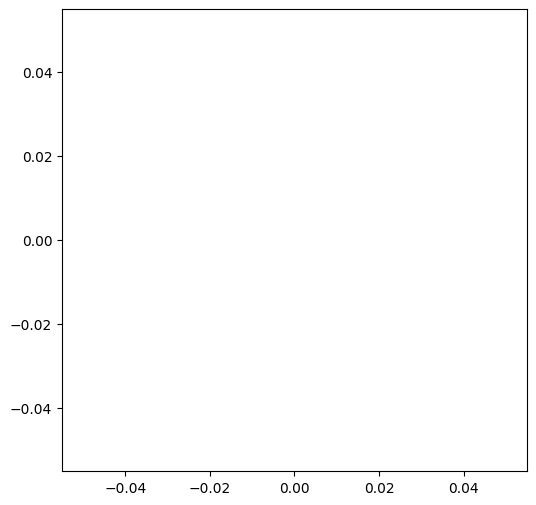

interactive(children=(FloatSlider(value=0.8, description='i_value', max=1.0, min=-1.0, step=0.01), FloatSlider…

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, Checkbox
from matplotlib.patches import Circle

# Initialize the plot variables
fig, ax = plt.subplots(figsize=(6, 6))
point, = ax.plot([], [], 'bo', markersize=10)
line, = ax.plot([], [], 'r-', lw=2)

def draw_iq_circle():
    ax.clear()
    ax.axhline(0, color='k', lw=0.5)
    ax.axvline(0, color='k', lw=0.5)
    circle = Circle((0, 0), 1, color='orange', fill=False, lw=1)
    ax.add_patch(circle)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal', 'box')
    ax.set_title("IQ Constellation")

def update_plot(i_value, q_value, show_constellation, show_noise, frequency):
    r = np.sqrt(i_value**2 + q_value**2)
    theta = np.degrees(np.arctan2(q_value, i_value))

    # Clear and redraw IQ circle
    draw_iq_circle()

    # Optionally show constellation points
    if show_constellation:
        # Display example 16-QAM constellation points
        const_points = [(i/3, q/3) for i in [-3, -1, 1, 3] for q in [-3, -1, 1, 3]]
        ax.plot([p[0] for p in const_points], [p[1] for p in const_points], 'ro', alpha=0.5)
    
    # Update the point and vector on the circle
    point.set_data([i_value], [q_value])  # Wrap i_value and q_value in lists
    line.set_data([0, i_value], [0, q_value])
    ax.plot([i_value], [q_value], 'bo')
    ax.plot([0, i_value], [0, q_value], 'r-', lw=2)
    ax.text(0.5, 1.1, f"x = {i_value:.2f} + j{q_value:.2f}", fontsize=12)
    ax.text(0.5, 0.9, f"|r| = {r:.2f}  θ = {theta:.1f}°", fontsize=12)

    # Generate time axis and signals
    t = np.linspace(0, 1, 1000)
    sine_wave = np.sin(2 * np.pi * frequency * t)
    cosine_wave = np.cos(2 * np.pi * frequency * t)
    iq_wave = i_value * cosine_wave + q_value * sine_wave

    # Optionally add noise
    if show_noise:
        noise = np.random.normal(0, 0.1, iq_wave.shape)
        sine_wave += noise
        cosine_wave += noise
        iq_wave += noise

    # Plot the signals
    fig, axs = plt.subplots(3, 1, figsize=(10, 6))
    axs[0].plot(t, sine_wave)
    axs[0].set_title("Sine")
    
    axs[1].plot(t, cosine_wave)
    axs[1].set_title("Cosine")
    
    axs[2].plot(t, iq_wave)
    axs[2].set_title("Sine + Cosine (IQ)")

    plt.tight_layout()
    plt.show()

# Interactive function for dragging
def on_click(event):
    if event.inaxes == ax:
        i_value = event.xdata
        q_value = event.ydata
        interact(update_plot, i_value=FloatSlider(value=i_value, min=-1, max=1, step=0.01), 
                 q_value=FloatSlider(value=q_value, min=-1, max=1, step=0.01),
                 show_constellation=Checkbox(value=True), show_noise=Checkbox(value=False),
                 frequency=FloatSlider(value=1.0, min=0.1, max=10, step=0.1))

# Initialize interactive widgets
interact(update_plot, i_value=FloatSlider(value=0.8, min=-1, max=1, step=0.01), 
         q_value=FloatSlider(value=0.33, min=-1, max=1, step=0.01),
         show_constellation=Checkbox(value=True), show_noise=Checkbox(value=False),
         frequency=FloatSlider(value=1.0, min=0.1, max=10, step=0.1))

draw_iq_circle()

fig.canvas.mpl_connect('button_press_event', on_click)
plt.show()


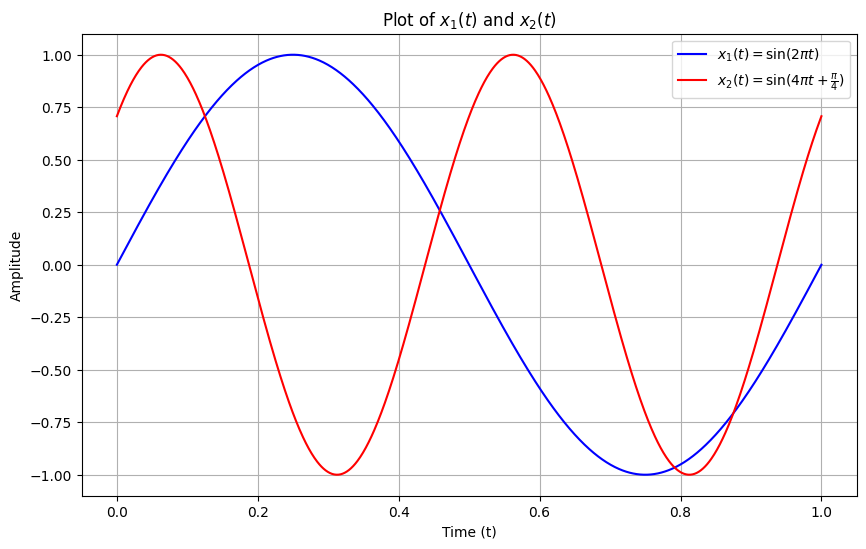

Inner product (integral of x1(t) * x2(t)): -9.352480039067553e-11
The signals x1(t) and x2(t) are orthogonal.


C:\Users\ilo_l\AppData\Local\Temp\ipykernel_25220\2838422282.py:35: DeprecationWarning: 'scipy.integrate.simps' is deprecated in favour of 'scipy.integrate.simpson' and will be removed in SciPy 1.14.0
  inner_product = simps(product, t)


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simps

# Define the time variable over one period
t = np.linspace(0, 1, 1000)  # 0 to 1 second, 1000 points

# Define the functions
x1 = np.sin(2 * np.pi * t)
x2 = np.sin(4 * np.pi * t + np.pi / 4)

# Plot the functions
plt.figure(figsize=(10, 6))

# Plot x1(t)
plt.plot(t, x1, label=r'$x_1(t) = \sin(2\pi t)$', color='blue')

# Plot x2(t)
plt.plot(t, x2, label=r'$x_2(t) = \sin(4\pi t + \frac{\pi}{4})$', color='red')

# Add labels and title
plt.title('Plot of $x_1(t)$ and $x_2(t)$')
plt.xlabel('Time (t)')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')

# Show grid
plt.grid(True)

# Show the plot
plt.show()

# Orthogonality check: Compute the inner product using numerical integration
product = x1 * x2
inner_product = simps(product, t)  

# Print the result
print(f"Inner product (integral of x1(t) * x2(t)): {inner_product}")

if np.isclose(inner_product, 0, atol=1e-10):
    print("The signals x1(t) and x2(t) are orthogonal.")
else:
    print("The signals x1(t) and x2(t) are NOT orthogonal.")


Here is a circular representation of WiFi channels and their corresponding center frequencies. Each point on the circle represents a WiFi channel, with the frequency labeled in MHz. The lines radiating from the center to each channel point help visualize the relationship between channels in a circular manner.

Channels: 1 to 11 are represented around the circle.
Frequencies: The center frequency for each channel is indicated next to it.
This diagram should help you visualize how channels and frequencies relate to each other in the context of WiFi networks. The circular layout is just one way to represent this relationship, with each channel spaced according to its frequency in the 2.4 GHz band.

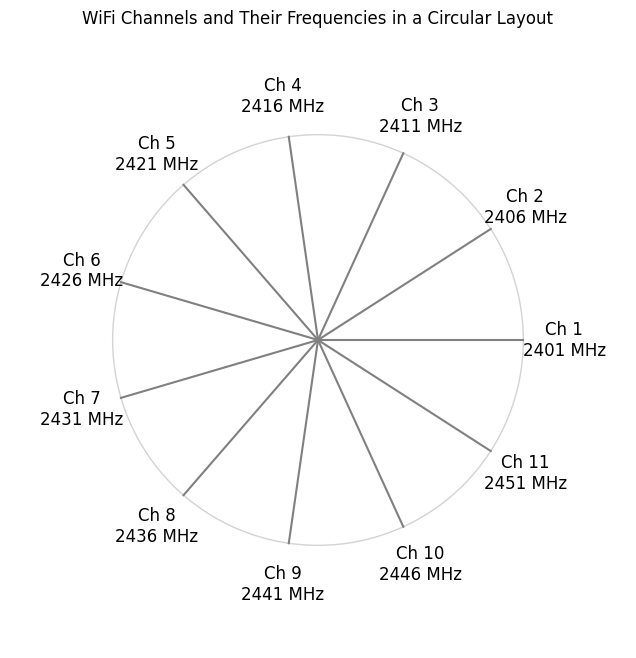

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
channels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
frequencies = [2401 + 5 * (ch - 1) for ch in channels]  # Calculate the center frequency for each channel

# Create a circular plot
fig, ax = plt.subplots(figsize=(8, 8))

# Create a circle
circle = plt.Circle((0, 0), 1, color='lightgray', fill=False)
ax.add_artist(circle)

# Plot channels as points on the circle
for i, (ch, freq) in enumerate(zip(channels, frequencies)):
    angle = 2 * np.pi * i / len(channels)
    x = np.cos(angle)
    y = np.sin(angle)
    ax.plot([0, x], [0, y], 'gray')  # Line from center to channel point
    ax.text(1.2 * x, 1.2 * y, f"Ch {ch}\n{freq} MHz", ha='center', va='center', fontsize=12)

# Set limits and aspect ratio
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect('equal', 'box')

# Hide axes
ax.axis('off')

# Title
plt.title("WiFi Channels and Their Frequencies in a Circular Layout")

# Show the plot
plt.show()
